# EDA de extracción y transformación: ETL MIO Cali

**Proyecto:** Análisis de la operación y la accesibilidad del Sistema Integrado de Transporte Masivo MIO de Cali
**Curso:** ETL, Universidad Autónoma de Occidente
**Integrante:** Jean Paul Tapia Ruiz

Este notebook es el **análisis exploratorio (EDA)** que justifica cada transformación del pipeline. Para cada fuente se revisa:

1. **Cómo llegan los datos (capa Bronze):** estructura, tipos, nulos, duplicados y rangos.
2. **Qué problemas tienen:** columnas vacías, llaves que no cruzan, horarios solapados, coordenadas, etc.
3. **Qué transformación se aplicó y por qué (capa Silver).**
4. **Cómo queda el resultado integrado (capa Gold)** y qué preguntas de negocio de la ficha ya se pueden responder.

> Antes de abrir el notebook hay que correr `python main.py`, que genera las carpetas `data/bronze`, `data/silver`, `data/gold` y `data/logs`.

## 0. Arquitectura y fuentes

| Capa | Contenido | Archivos |
|---|---|---|
| **Bronze** | Datos tal como llegan de la fuente | `api_stops_raw.*`, `api_lines_raw.*`, `gtfs_mio_source.zip`, `gtfs_*_raw.csv` |
| **Silver** | Datos limpios, tipados y con nombres estándar GTFS | `*_silver.csv` |
| **Gold** | Tablas integradas para análisis + KPIs | `gold_final.csv` (paradas), `gold_rutas.csv`, `gold_servicios_hora.csv`, `kpis.json` |
| **Logs** | Trazabilidad de cada ejecución | `etl.log`, `run_<id>.log`, `quality_report_<id>.json` |

**Fuente 1, API REST ArcGIS (GTFS Cali, vigencia 2025):** capa 0 *Stops* (paradas con coordenadas) y capa 4 *Lines* (rutas).
**Fuente 2, feed GTFS público (ColombiaGTFS, vigencia 2017-2021):** `stops`, `routes`, `trips`, `stop_times`, `calendar`.

In [1]:
import json, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Raíz del proyecto (funciona si el notebook se abre desde /notebooks o desde la raíz)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "main.py").exists())
B, S, G = (ROOT / "data" / x for x in ("bronze", "silver", "gold"))
LG = ROOT / "logs"

# Estilo de gráficas: marcas delgadas, grilla tenue, paleta fija
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#a3a29c", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})
pd.set_option("display.max_columns", 30)

def resumen(df, nombre):
    """Perfil de columnas: tipo, nulos, % nulos, valores únicos y ejemplo."""
    r = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "%_nulos": (df.isna().mean() * 100).round(1),
        "unicos": df.nunique(),
        "ejemplo": df.apply(lambda c: c.dropna().iloc[0] if c.notna().any() else None),
    })
    print(f"{nombre}: {df.shape[0]:,} filas x {df.shape[1]} columnas | filas duplicadas: {df.duplicated().sum()}")
    return r

## 1. Fuente 1: API ArcGIS, capa de paradas (Bronze)

In [2]:
api_raw = pd.read_csv(B / "api_stops_raw.csv", dtype=str)
api_raw.head()

,OBJECTID,ID,GStopID,GStopType,GStopParen,ParentID,GWheelchairBoarding,longitude,latitude
0,1,2001,519075,0,NaN,NaN,NaN,-76.55648639038648,3.4480452802427637
1,2,2002,519076,0,NaN,NaN,NaN,-76.55364417023485,3.4497586103693068
2,3,2003,519077,0,NaN,NaN,NaN,-76.55087777957134,3.4510866699674403
3,4,2004,519078,0,NaN,NaN,NaN,-76.54881972039077,3.4518680599657414
4,5,2005,519079,0,NaN,NaN,NaN,-76.53994056012013,3.4504069403100037


In [3]:
resumen(api_raw, "api_stops_raw")

api_stops_raw: 2,107 filas x 9 columnas | filas duplicadas: 0


,tipo,nulos,%_nulos,unicos,ejemplo
OBJECTID,str,0,0.0,2107,1
ID,str,0,0.0,2107,2001
GStopID,str,0,0.0,2107,519075
GStopType,str,0,0.0,2,0
GStopParen,str,1970,93.5,30,50010
ParentID,str,1970,93.5,30,9.0
GWheelchairBoarding,str,2107,100.0,0,NaN
longitude,str,0,0.0,2090,-76.55648639038648
latitude,str,0,0.0,2097,3.4480452802427637


In [4]:
# Metadatos de los campos que publica la API (alias = significado real de la columna)
meta = json.loads((B / "api_stops_raw.json").read_text(encoding="utf-8"))
pd.DataFrame([(f["name"], f.get("alias", "").strip(), f["type"].replace("esriFieldType", "")) for f in meta["fields"]],
             columns=["columna_api", "alias", "tipo"])

,columna_api,alias,tipo
0,OBJECTID,OBJECTID,OID
1,ID,Identificador,Integer
2,GStopID,StopID,String
3,GStopType,Location_type,SmallInteger
4,GStopParen,Parent_station,String
5,ParentID,Platform_code,Integer
6,GWheelchairBoarding,Wheel Chair Boarding,SmallInteger


### Hallazgos en la API

- **La capa de paradas no trae nombre de parada.** Solo tiene identificadores (`OBJECTID`, `ID`, `GStopID`), tipo y coordenadas.
  👉 Por eso la versión anterior del pipeline, que unía por *nombre normalizado*, generaba una tabla Gold con **0 filas**: no había nombres que comparar, y el filtro `nombre_norm != ""` eliminaba las 2.000 paradas.
- Según los metadatos, **`GStopID` es el `stop_id` del estándar GTFS** (*"Llave primaria. Identificador de la parada física"*). Esa es la llave correcta para integrar con la fuente 2.
- `GWheelchairBoarding` (accesibilidad en silla de ruedas) está **100 % vacía**: no aporta información y se elimina en Silver.
- `GStopParen` y `ParentID` están vacías en ~93 % de los casos. Es lo esperado: solo las paradas que pertenecen a una estación tienen "padre".
- La respuesta original traía `exceededTransferLimit = true`: la API corta en 2.000 registros. **Se agregó paginación** (`resultOffset`) para descargar todas las páginas.

In [5]:
api_raw["GStopType"].value_counts().rename({"0": "0 = parada", "1": "1 = estación"}).to_frame("cantidad")

,cantidad
GStopType,
0 = parada,2074
1 = estación,33


## 2. Fuente 2: feed GTFS (Bronze)

El ZIP trae 7 archivos. Los pequeños se extraen a CSV en Bronze; `stop_times.txt` (≈155 MB, ≈3 millones de filas) se procesa por bloques directamente desde el ZIP.

In [6]:
with zipfile.ZipFile(B / "gtfs_mio_source.zip") as z:
    archivos = pd.DataFrame([(i.filename, round(i.file_size / 1e6, 2)) for i in z.infolist()], columns=["archivo", "MB"])
archivos

,archivo,MB
0,agency.txt,0.00
1,calendar.txt,0.00
2,feed_info.txt,0.00
3,routes.txt,0.01
4,stop_times.txt,154.77
5,stops.txt,0.12
6,trips.txt,9.61


In [7]:
gtfs_stops_raw = pd.read_csv(B / "gtfs_stops_raw.csv", dtype=str)
resumen(gtfs_stops_raw, "gtfs_stops_raw")

gtfs_stops_raw: 2,048 filas x 7 columnas | filas duplicadas: 0


,tipo,nulos,%_nulos,unicos,ejemplo
stop_id,str,0,0.0,2048,1000
stop_name,str,0,0.0,2003,Alamos
stop_lat,str,0,0.0,2037,3.48457417
stop_lon,str,0,0.0,2036,-76.51331833
location_type,str,0,0.0,2,1
parent_station,str,1849,90.3,60,1043
platform_code,str,1849,90.3,28,A2


In [8]:
routes_raw = pd.read_csv(B / "gtfs_routes_raw.csv", dtype=str)
trips_raw = pd.read_csv(B / "gtfs_trips_raw.csv", dtype=str)
cal_raw = pd.read_csv(B / "gtfs_calendar_raw.csv", dtype=str)
display(resumen(routes_raw, "routes_raw"))
display(resumen(trips_raw, "trips_raw"))

routes_raw: 97 filas x 6 columnas | filas duplicadas: 0


,tipo,nulos,%_nulos,unicos,ejemplo
route_id,str,0,0.0,97,3011
route_short_name,str,0,0.0,97,A01A
route_long_name,str,0,0.0,87,San Bosco - C.A.M - Centro
route_type,str,0,0.0,1,3
route_color,str,0,0.0,4,08A300
route_text_color,str,0,0.0,2,FFFFFF


trips_raw: 139,277 filas x 6 columnas | filas duplicadas: 0


,tipo,nulos,%_nulos,unicos,ejemplo
route_id,str,0,0.0,97,3011
service_id,str,0,0.0,9,4612024
trip_id,str,0,0.0,139277,3011-252-1-4612024
trip_headsign,str,0,0.0,138,San Bosco B1
direction_id,str,0,0.0,2,1
block_id,str,18537,13.3,28208,252_4612024-1


In [9]:
# Muestra de stop_times (solo las primeras 200.000 filas para explorar)
with zipfile.ZipFile(B / "gtfs_mio_source.zip") as z:
    st_sample = pd.read_csv(z.open("stop_times.txt"), dtype=str, nrows=200_000)
display(st_sample.head())
resumen(st_sample, "stop_times (muestra)")

,trip_id,arrival_time,departure_time,stop_id,stop_sequence,stop_headsign
0,3011-252-1-4612024,05:15:00,05:15:00,501001,1,Torre de Cali B1
1,3011-252-1-4612024,05:18:19,05:18:19,501405,2,Torre de Cali B1
2,3011-252-1-4612024,05:20:19,05:20:19,501451,3,Torre de Cali B1
3,3011-252-1-4612024,05:22:09,05:22:09,501502,4,Torre de Cali B1
4,3011-252-1-4612024,05:24:08,05:24:08,501551,5,Torre de Cali B1


stop_times (muestra): 200,000 filas x 6 columnas | filas duplicadas: 0


,tipo,nulos,%_nulos,unicos,ejemplo
trip_id,str,0,0.0,13685,3011-252-1-4612024
arrival_time,str,0,0.0,37117,05:15:00
departure_time,str,0,0.0,37117,05:15:00
stop_id,str,0,0.0,203,501001
stop_sequence,str,0,0.0,22,1
stop_headsign,str,178211,89.1,6,Torre de Cali B1


### Hallazgos en el GTFS

- `stops`: sin nulos en id, nombre ni coordenadas, y sin `stop_id` duplicados. Sí hay **nombres repetidos**: paradas distintas con el mismo nombre (por ejemplo, las dos aceras de una misma calle). Esto confirma que **el nombre no sirve como llave**.
- `trips.block_id` tiene nulos: es un campo opcional en GTFS y no se usa en el análisis.
- `stop_times.stop_headsign` está casi todo vacío (campo opcional), así que no se carga.
- Los horarios vienen como texto `HH:MM:SS` y pueden pasar de 24:00 (servicios después de medianoche, permitido por GTFS). Se convierten a **segundos** para poder calcular duraciones.

In [10]:
dup_nombres = gtfs_stops_raw[gtfs_stops_raw["stop_name"].str.strip().str.lower().duplicated(keep=False)]
print(f"Paradas con nombre repetido: {len(dup_nombres)} ({dup_nombres['stop_name'].nunique()} nombres distintos)")
dup_nombres.sort_values("stop_name").head(8)[["stop_id", "stop_name", "stop_lat", "stop_lon"]]

Paradas con nombre repetido: 92 (47 nombres distintos)


,stop_id,stop_name,stop_lat,stop_lon
1973,519123,Av 2 Oeste con Cl 20,3.447625,-76.561435
1975,519125,Av 2 Oeste con Cl 20,3.44767,-76.56177167
622,512005,Av 6AN entre Cl 35 y 29 PP1,3.4732275,-76.52766389
946,513271,Av 6AN entre Cl 35 y 29 PP1,3.47155639,-76.52892417
734,512203,Av 6AN entre Cl 35 y 29 PP2,3.47307167,-76.52784333
735,512204,Av 6AN entre Cl 35 y 29 PP2,3.4714275,-76.52900222
358,511139,Av los Cerros con Cl 2 Acceso Vial,3.348335,-76.55718222
369,511150,Av los Cerros con Cl 2 Acceso Vial,3.348085,-76.55664444


## 3. ¿Por qué llave se unen las dos fuentes?

Se comparan tres candidatas para cruzar la API con el GTFS:

In [11]:
g_ids = set(gtfs_stops_raw["stop_id"])
cand = pd.DataFrame({
    "llave_api": ["nombre (no existe)", "ID", "GStopID"],
    "coincidencias": [0, api_raw["ID"].isin(g_ids).sum(), api_raw["GStopID"].isin(g_ids).sum()],
})
cand["%_de_paradas_api"] = (100 * cand["coincidencias"] / len(api_raw)).round(1)
cand

,llave_api,coincidencias,%_de_paradas_api
0,nombre (no existe),0,0.0
1,ID,60,2.8
2,GStopID,1612,76.5


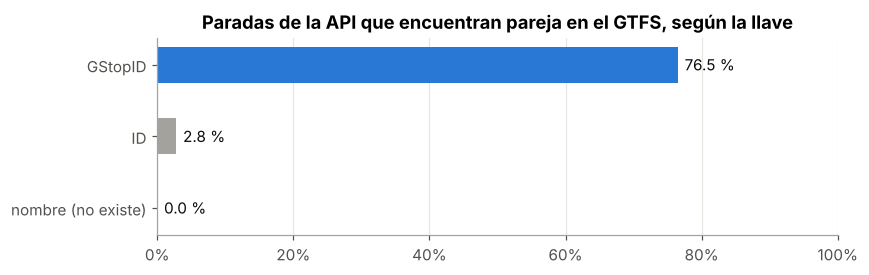

In [12]:
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh(cand["llave_api"], cand["%_de_paradas_api"], color=[GRIS, GRIS, AZUL], height=0.5)
for y, v in enumerate(cand["%_de_paradas_api"]):
    ax.text(v + 1, y, f"{v:.1f} %", va="center", color="#0b0b0b")
ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Paradas de la API que encuentran pareja en el GTFS, según la llave")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

**Decisión:** se une por `GStopID (API) = stop_id (GTFS)`. Con esa llave **el 76 % de las paradas de la API se encuentra en el GTFS**. El 24 % restante no es un error: el GTFS es de 2017-2021 y la API de 2025, así que hay paradas nuevas y paradas retiradas.

Para validar que la llave es correcta, se mide la **distancia en metros** entre la coordenada de la API y la del GTFS para la misma parada (sección 6).

## 4. Transformaciones aplicadas (Bronze → Silver)

El pipeline registra cada regla en `data/logs/quality_report_latest.json`. Esta tabla sale directamente de ese reporte:

In [13]:
qr = json.loads((LG / "quality_report_latest.json").read_text(encoding="utf-8"))
pasos = pd.DataFrame(qr["pasos"])
tabla = pasos[pasos["etapa"].isin(["transform_silver", "transform_gold"])][
    ["etapa", "tabla", "filas_entrada", "filas_salida", "filas_descartadas", "detalle"]]
tabla

,etapa,tabla,filas_entrada,filas_salida,filas_descartadas,detalle
10,transform_silver,api_stops,2107,2107,0,{'columnas_vacias_eliminadas': ['wheelchair_bo...
11,transform_silver,gtfs_stops,2048,2048,0,"{'id_o_nombre_nulo': 0, 'stop_id_duplicado': 0..."
12,transform_silver,routes,97,97,0,"{'route_id_nulo': 0, 'route_id_duplicado': 0}"
13,transform_silver,calendar,10,10,0,NaN
14,transform_silver,trips,139277,139277,0,"{'trip_id_duplicado': 0, 'ruta_inexistente': 0..."
15,transform_silver,stop_times,2987216,2987216,0,"{'filas_leidas': 2987216, 'hora_invalida': 0, ..."
22,transform_gold,gold_paradas,4155,2543,1612,NaN
23,transform_gold,asignacion_comunas,2543,2280,263,NaN
24,transform_gold,gold_comunas,2543,23,2520,NaN
26,transform_gold,gold_accesibilidad,22,23,-1,NaN


### Reglas por tabla

| Tabla | Transformación | Justificación (EDA) |
|---|---|---|
| **api_stops** | Renombrar a estándar GTFS (`GStopID→stop_id`, `GStopType→location_type`, `latitude→stop_lat`…) | Permite unir con el GTFS usando los mismos nombres de columna |
| | Eliminar `wheelchair_boarding` | 100 % nula |
| | Convertir coordenadas a número y validar que estén dentro de Cali (lat 3.25-3.55, lon -76.65 a -76.40) | Evita puntos fuera de la ciudad |
| | Quitar `stop_id` nulos y duplicados | La llave debe ser única |
| | `tipo_parada` = parada / estación | Código 0/1 traducido a texto |
| **gtfs_stops** | Quitar espacios, tipar coordenadas, validar rango, quitar nulos y duplicados | Mismas reglas que la API, para que ambas queden comparables |
| | `nombre_norm` (minúsculas, sin tildes) | Solo para búsquedas; **no** se usa como llave porque hay nombres repetidos |
| **routes** | `tipo_servicio` según la letra inicial (T=Troncal, P=Pretroncal, A=Alimentadora, E=Expresa) | Permite analizar la cobertura por tipo de servicio |
| **calendar** | Fechas a `datetime`; `tipo_dia` = hábil / sábado / domingo-festivo | Agrupa los servicios por tipo de día |
| **trips** | Integridad referencial: la ruta y el servicio deben existir | Evita viajes huérfanos |
| **stop_times** | Horas a segundos (admite > 24 h); agregación por viaje: inicio, fin, duración y número de paradas; pares ruta-parada | ≈3 M filas → 139 mil viajes; se descartan viajes con duración ≤ 0 |

In [14]:
api_s = pd.read_csv(S / "api_stops_silver.csv", dtype={"stop_id": str})
g_s = pd.read_csv(S / "gtfs_stops_silver.csv", dtype={"stop_id": str})
antes_despues = pd.DataFrame({
    "columnas_bronze": [api_raw.shape[1], gtfs_stops_raw.shape[1]],
    "columnas_silver": [api_s.shape[1], g_s.shape[1]],
    "filas_bronze": [len(api_raw), len(gtfs_stops_raw)],
    "filas_silver": [len(api_s), len(g_s)],
}, index=["api_stops", "gtfs_stops"])
display(antes_despues)
print("Tipos en Silver (API):"); print(api_s.dtypes.to_string())

,columnas_bronze,columnas_silver,filas_bronze,filas_silver
api_stops,9,9,2107,2107
gtfs_stops,7,9,2048,2048


Tipos en Silver (API):
api_objectid        int64
api_id              int64
stop_id               str
location_type       int64
parent_station    float64
platform_code     float64
stop_lon          float64
stop_lat          float64
tipo_parada           str


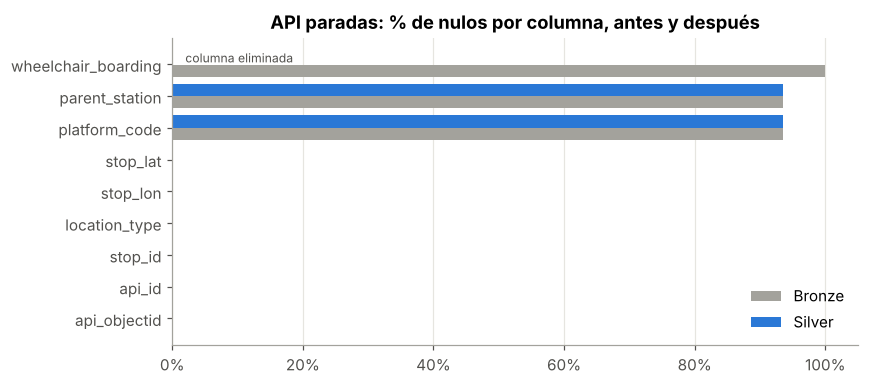

In [15]:
# Nulos antes y después en la API
nul = pd.DataFrame({"bronze": api_raw.isna().mean() * 100})
nul.index = nul.index.map({"OBJECTID": "api_objectid", "ID": "api_id", "GStopID": "stop_id", "GStopType": "location_type",
                           "GStopParen": "parent_station", "ParentID": "platform_code",
                           "GWheelchairBoarding": "wheelchair_boarding", "latitude": "stop_lat", "longitude": "stop_lon"})
nul["silver"] = (api_s.isna().mean() * 100).reindex(nul.index)
nul = nul.sort_values("bronze")
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(nul))
ax.barh(y - 0.2, nul["bronze"], height=0.38, color=GRIS, label="Bronze")
ax.barh(y + 0.2, nul["silver"].fillna(0), height=0.38, color=AZUL, label="Silver")
for i, (b, s) in enumerate(zip(nul["bronze"], nul["silver"])):
    if pd.isna(s): ax.text(2, i + 0.2, "columna eliminada", va="center", fontsize=8, color="#52514e")
ax.set_yticks(y, nul.index); ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlim(0, 105)
ax.set_title("API paradas: % de nulos por columna, antes y después"); ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

Los nulos que quedan en `parent_station` y `platform_code` **se conservan a propósito**: indican que la parada no pertenece a una estación. Imputarlos sería inventar información.

## 5. Horarios: problema de servicios solapados

En `calendar` hay **varios `service_id` para el mismo tipo de día** (tres para día hábil, tres para sábado y cuatro para domingo). Todos cubren las mismas rutas y casi el mismo número de viajes: son versiones alternativas de la programación.

In [16]:
cal = pd.read_csv(S / "calendar_silver.csv", dtype={"service_id": str})
trips = pd.read_csv(S / "trips_silver.csv", dtype={"service_id": str, "route_id": str, "trip_id": str})
v = trips.groupby(["tipo_dia", "service_id"]).agg(viajes=("trip_id", "size"), rutas=("route_id", "nunique")).reset_index()
v.merge(cal[["service_id", "monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]], on="service_id")

,tipo_dia,service_id,viajes,rutas,monday,tuesday,wednesday,thursday,friday,saturday,sunday
0,domingo_festivo,4612026,10873,76,0,0,0,0,0,0,1
1,domingo_festivo,4612095,10885,76,0,0,0,0,0,0,1
2,domingo_festivo,4612107,10873,76,0,0,0,0,0,0,1
3,habil,4612024,20112,94,0,1,1,1,1,0,0
4,habil,4612105,20112,94,1,1,1,1,1,0,0
5,habil,4652041,20069,94,1,1,1,1,1,0,0
6,sabado,4612027,15471,90,0,0,0,0,0,1,0
7,sabado,4612106,15471,90,0,0,0,0,0,1,0
8,sabado,4652042,15411,90,0,0,0,0,0,1,0


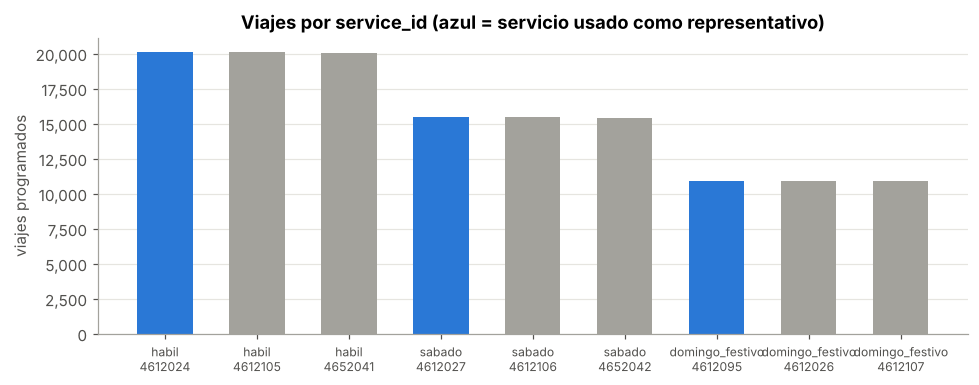

Si se suman todos los servicios hábiles: 60293 viajes/día (sobreestimado ×3)


In [17]:
sel = qr["servicios_representativos"]
v["representativo"] = v["service_id"].isin(sel.values())
orden = ["habil", "sabado", "domingo_festivo"]
v = v.sort_values(["tipo_dia", "viajes"], key=lambda s: s.map({k: i for i, k in enumerate(orden)}) if s.name == "tipo_dia" else -s)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(len(v)), v["viajes"], color=np.where(v["representativo"], AZUL, GRIS), width=0.6)
ax.set_xticks(range(len(v)), [f"{t}\n{s}" for t, s in zip(v["tipo_dia"], v["service_id"])], fontsize=8)
ax.set_ylabel("viajes programados"); ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Viajes por service_id (azul = servicio usado como representativo)")
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()
print("Si se suman todos los servicios hábiles:", v.loc[v.tipo_dia == "habil", "viajes"].sum(), "viajes/día (sobreestimado ×3)")

**Decisión:** para calcular frecuencias **se toma un solo `service_id` por tipo de día** (el de más viajes). Sumarlos todos triplicaría la frecuencia real de un día hábil. La elección queda registrada en el log y en `kpis.json`.

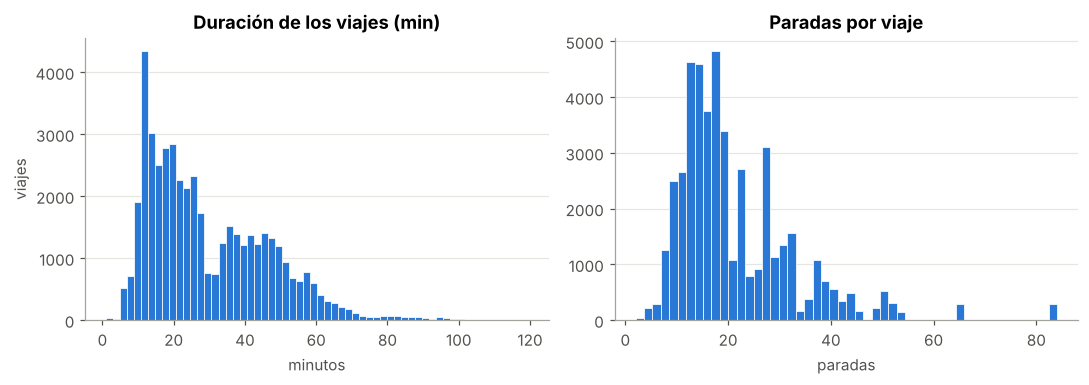

,duracion_min,n_paradas
count,46468.0,46468.0
mean,29.6,21.4
std,17.0,11.7
min,1.0,2.0
25%,15.7,14.0
50%,24.8,18.0
75%,41.6,28.0
max,119.3,84.0


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
rep = trips[trips["service_id"].isin(sel.values())]
axes[0].hist(rep["duracion_min"], bins=60, color=AZUL, edgecolor="white", linewidth=0.5)
axes[0].set_title("Duración de los viajes (min)"); axes[0].set_xlabel("minutos"); axes[0].set_ylabel("viajes")
axes[1].hist(rep["n_paradas"], bins=50, color=AZUL, edgecolor="white", linewidth=0.5)
axes[1].set_title("Paradas por viaje"); axes[1].set_xlabel("paradas")
for a in axes: a.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
rep[["duracion_min", "n_paradas"]].describe().round(1)

In [19]:
# Revisión de valores atípicos con el criterio de IQR (se reportan, no se eliminan)
q1, q3 = rep["duracion_min"].quantile([.25, .75]); lim = q3 + 1.5 * (q3 - q1)
atip = rep[rep["duracion_min"] > lim]
print(f"Límite superior IQR: {lim:.1f} min | viajes por encima: {len(atip)} ({100*len(atip)/len(rep):.1f} %)")
atip.merge(pd.read_csv(S / "routes_silver.csv", dtype={"route_id": str})[["route_id", "route_short_name", "tipo_servicio"]], on="route_id") \
    .groupby(["route_short_name", "tipo_servicio"]).size().sort_values(ascending=False).head(8).to_frame("viajes_largos")

Límite superior IQR: 80.4 min | viajes por encima: 491 (1.1 %)


,,viajes_largos
route_short_name,tipo_servicio,
P12A,Pretroncal,459
P27C,Pretroncal,17
P27D,Pretroncal,7
P21A,Pretroncal,4
P72,Pretroncal,3
P47C,Pretroncal,1


Los viajes largos corresponden a rutas de recorrido extenso (pretroncales y algunas troncales que cruzan la ciudad), no a errores de captura. Por eso **se conservan**. Solo se eliminan viajes con duración ≤ 0, que serían físicamente imposibles.

## 6. Gold: integración de paradas (`gold_final.csv`)

In [20]:
gold = pd.read_csv(G / "gold_final.csv", dtype={"stop_id": str})
display(gold.head())
gold["presencia"].value_counts().to_frame("paradas")

,stop_id,stop_name,stop_lat_gtfs,stop_lon_gtfs,parent_station,api_id,stop_lat_api,stop_lon_api,presencia,distancia_m,lat,lon,fuente_coord,tipo_parada,n_rutas,comuna
0,1000,Alamos,3.484574,-76.513318,NaN,NaN,NaN,NaN,solo_gtfs,NaN,3.484574,-76.513318,gtfs,estacion,0,Comuna 02
1,1001,Amanecer,3.421511,-76.490829,NaN,NaN,NaN,NaN,solo_gtfs,NaN,3.421511,-76.490829,gtfs,estacion,0,Comuna 13
2,1002,Atanasio Girardot,3.444832,-76.508283,NaN,NaN,NaN,NaN,solo_gtfs,NaN,3.444832,-76.508283,gtfs,estacion,0,Comuna 08
3,1003,Belalcazar,3.444158,-76.520687,NaN,NaN,NaN,NaN,solo_gtfs,NaN,3.444158,-76.520687,gtfs,estacion,0,Comuna 09
4,1004,Buitrera,3.372682,-76.540235,NaN,NaN,NaN,NaN,solo_gtfs,NaN,3.372682,-76.540235,gtfs,estacion,0,Comuna 22


,paradas
presencia,
ambas,1612
solo_api,495
solo_gtfs,436


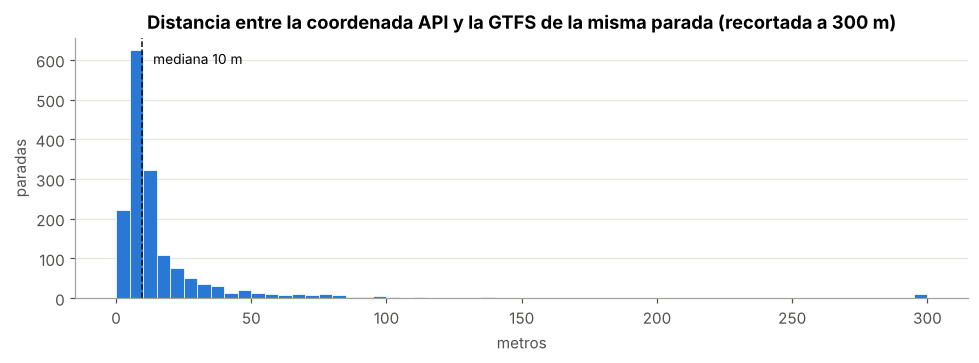

count    1612.0
mean       19.6
std        45.2
min         0.0
50%         9.7
90%        37.9
95%        62.8
99%       171.7
max       845.1


In [21]:
amb = gold[gold["presencia"] == "ambas"]["distancia_m"]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(amb.clip(upper=300), bins=60, color=AZUL, edgecolor="white", linewidth=0.5)
ax.axvline(amb.median(), color="#0b0b0b", linewidth=1, linestyle="--")
ax.text(amb.median() + 4, ax.get_ylim()[1] * 0.9, f"mediana {amb.median():.0f} m", fontsize=9)
ax.set_title("Distancia entre la coordenada API y la GTFS de la misma parada (recortada a 300 m)")
ax.set_xlabel("metros"); ax.set_ylabel("paradas"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(amb.describe(percentiles=[.5, .9, .95, .99]).round(1).to_string())

**Validación de la llave:** la mediana de distancia es de unos 10 m y el 95 % de las paradas está a menos de ~65 m. Esto confirma que `GStopID = stop_id` identifica la **misma parada física** en ambas fuentes. Las pocas paradas a más de 200 m probablemente se reubicaron entre 2021 y 2025; quedan marcadas en el log.

**Coordenada final:** se usa la de la API (más reciente, 2025) y, si no existe, la del GTFS (`fuente_coord`).

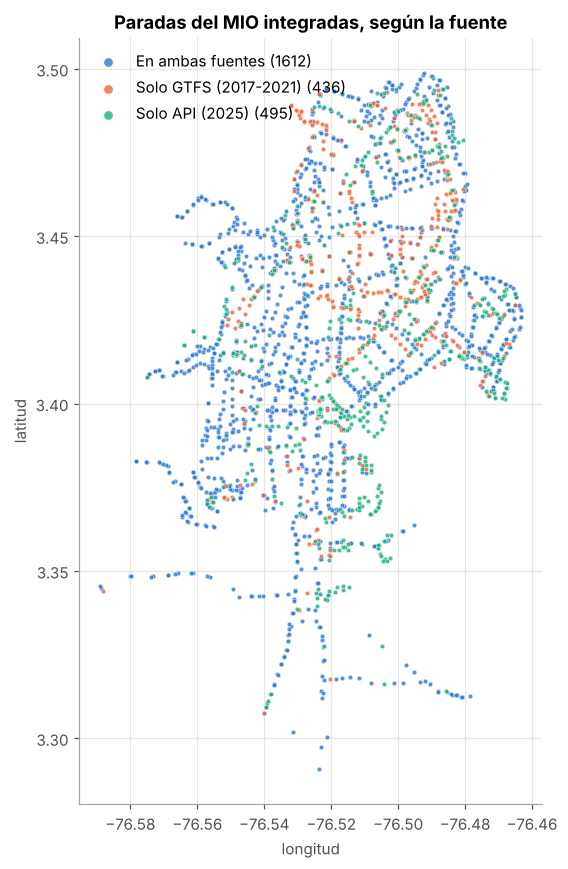

In [22]:
fig, ax = plt.subplots(figsize=(7, 8))
colores = {"ambas": AZUL, "solo_gtfs": NARANJA, "solo_api": AQUA}
etq = {"ambas": "En ambas fuentes", "solo_gtfs": "Solo GTFS (2017-2021)", "solo_api": "Solo API (2025)"}
for k, c in colores.items():
    d = gold[gold["presencia"] == k]
    ax.scatter(d["lon"], d["lat"], s=9, color=c, alpha=0.8, linewidths=0.3, edgecolors="white", label=f"{etq[k]} ({len(d)})")
ax.set_aspect("equal"); ax.set_title("Paradas del MIO integradas, según la fuente")
ax.set_xlabel("longitud"); ax.set_ylabel("latitud"); ax.legend(frameon=False, loc="upper left", markerscale=2)
plt.tight_layout(); plt.show()

> ⚠️ Si la ejecución usó la copia Bronze sin paginar (ver advertencias del log), la API solo tiene las primeras 2.000 paradas. Al correr el pipeline con internet, la paginación descarga todas y estos números cambian.

## 7. Primeras respuestas a las preguntas de negocio de la ficha

In [23]:
rutas = pd.read_csv(G / "gold_rutas.csv", dtype={"route_id": str})
rutas[["route_short_name", "route_long_name", "tipo_servicio", "n_paradas", "viajes_dia_habil",
       "duracion_promedio_min", "intervalo_promedio_min", "en_api_2025"]].head()

,route_short_name,route_long_name,tipo_servicio,n_paradas,viajes_dia_habil,duracion_promedio_min,intervalo_promedio_min,en_api_2025
0,A01A,San Bosco - C.A.M - Centro,Alimentadora,12,115,23.0,18.1,True
1,A02,Atenas - Zoológico - Estación San Bosco,Alimentadora,30,300,19.3,7.6,True
2,A03,Nacional - Santa librada,Alimentadora,13,78,12.1,28.8,True
3,A04,Bella Vista - Estación Manzana del saber,Alimentadora,26,244,12.0,9.3,True
4,A05,Av. De Las Américas - C.A.M - La Portada,Alimentadora,22,207,15.4,10.9,True


### Pregunta 1: ¿Qué rutas tienen más paradas?

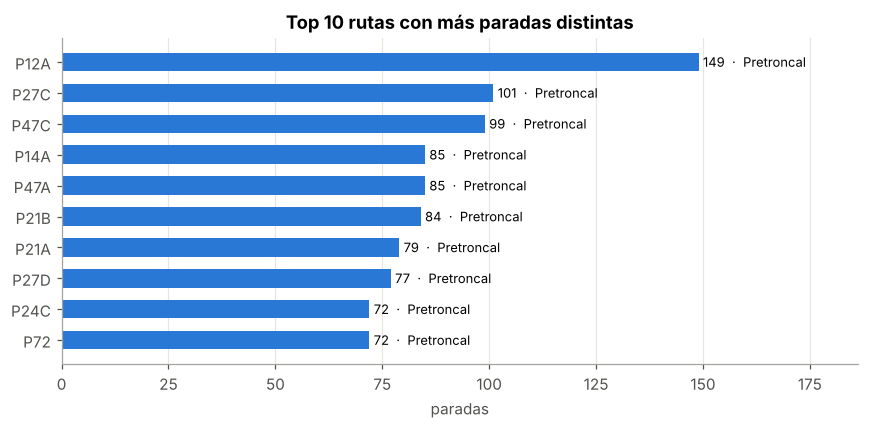

In [24]:
top = rutas.nlargest(10, "n_paradas").iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top["route_short_name"], top["n_paradas"], color=AZUL, height=0.6)
for y, (v, t) in enumerate(zip(top["n_paradas"], top["tipo_servicio"])):
    ax.text(v + 1, y, f"{v}  ·  {t}", va="center", fontsize=8.5)
ax.set_title("Top 10 rutas con más paradas distintas"); ax.set_xlabel("paradas"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, top["n_paradas"].max() * 1.25); plt.tight_layout(); plt.show()

### Pregunta 4: ¿En qué horarios se concentran los servicios programados?

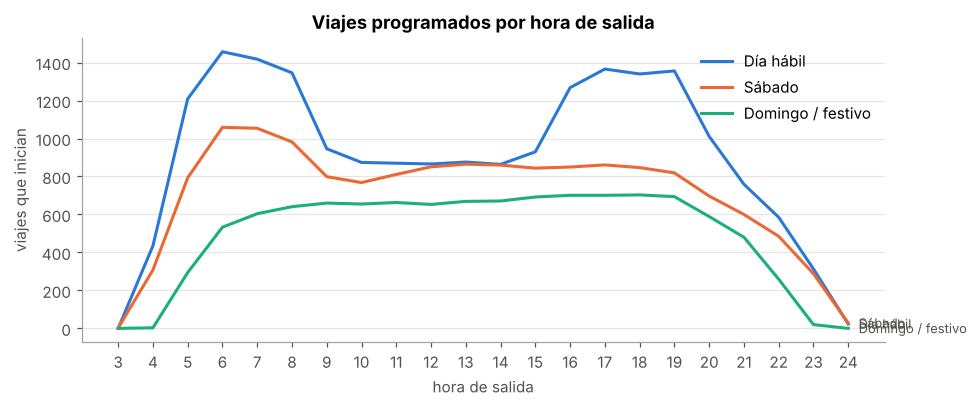

In [25]:
h = pd.read_csv(G / "gold_servicios_hora.csv")
piv = h.pivot(index="hora_inicio", columns="tipo_dia", values="viajes").fillna(0)
fig, ax = plt.subplots(figsize=(9, 3.8))
for col, c, lab in [("habil", AZUL, "Día hábil"), ("sabado", NARANJA, "Sábado"), ("domingo_festivo", AQUA, "Domingo / festivo")]:
    if col in piv:
        ax.plot(piv.index, piv[col], color=c, linewidth=2, label=lab)
        ax.text(piv.index[-1] + 0.3, piv[col].iloc[-1], lab, color="#52514e", fontsize=8.5, va="center")
ax.set_xticks(range(int(piv.index.min()), int(piv.index.max()) + 1))
ax.set_xlabel("hora de salida"); ax.set_ylabel("viajes que inician")
ax.set_title("Viajes programados por hora de salida"); ax.legend(frameon=False, loc="upper right")
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

El día hábil tiene dos picos marcados: **mañana (6:00-7:00)** y **tarde (17:00-19:00)**, el patrón típico de los viajes al trabajo y al estudio. Sábados y domingos tienen bastante menos oferta y no muestran el pico de la madrugada.

### Pregunta 5: ¿Qué rutas tienen mayor frecuencia de operación?

In [26]:
f = rutas[rutas["viajes_dia_habil"] > 0].nlargest(10, "viajes_dia_habil")
f[["route_short_name", "route_long_name", "tipo_servicio", "viajes_dia_habil", "intervalo_promedio_min",
   "primera_salida_h", "ultima_salida_h"]]

,route_short_name,route_long_name,tipo_servicio,viajes_dia_habil,intervalo_promedio_min,primera_salida_h,ultima_salida_h
40,A47,Pizamos - Terminal Andrés Sanín,Alimentadora,585,4.1,4.20,24.02
94,T47B,Terminal Andrés Sanín - Estación Unidad Deportiva,Troncal,488,4.6,4.67,23.40
15,A14A,U.S.B - Estación Universidades,Alimentadora,448,5.1,5.00,24.09
56,E21,Terminal Menga - Estación Universidades,Expresa,442,5.0,4.75,23.08
92,T40,Terminal Andrés Sanín - Centro,Troncal,391,5.4,4.90,22.35
96,T57A,Estación Nuevo Latír - Estación Unidad Deportiva,Troncal,378,5.9,4.68,23.41
91,T31,Terminal Paso del Comercio - Estación Universi...,Troncal,369,6.0,4.72,23.10
6,A11,Icesi - P.U.J - Estación Universidades,Alimentadora,363,6.4,4.64,23.93
60,E37,Terminal Paso del Comercio - Estación Universi...,Expresa,350,5.9,4.97,22.12
50,A73,Nápoles - Estación Caldas - Terminal Cañaveralejo,Alimentadora,346,6.6,4.60,23.70


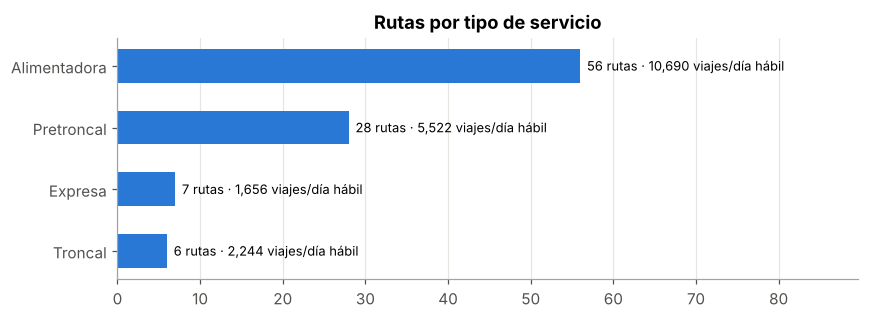

In [27]:
fig, ax = plt.subplots(figsize=(8, 3))
t = rutas.groupby("tipo_servicio").agg(rutas=("route_id", "size"), viajes=("viajes_dia_habil", "sum")).sort_values("rutas")
ax.barh(t.index, t["rutas"], color=AZUL, height=0.55)
for y, (r, vv) in enumerate(zip(t["rutas"], t["viajes"])):
    ax.text(r + 0.8, y, f"{r} rutas · {vv:,} viajes/día hábil", va="center", fontsize=8.5)
ax.set_xlim(0, t["rutas"].max() * 1.6); ax.set_title("Rutas por tipo de servicio"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 8. KPIs de la ficha calculados

In [28]:
k = json.loads((G / "kpis.json").read_text(encoding="utf-8"))
dur = k["KPI5_tiempo_recorrido_min"]
acc = k["KPI6_accesibilidad"]
pd.DataFrame([
    ["KPI 1: Número de rutas", k["KPI1_numero_rutas"], "Calculado"],
    ["KPI 2: Número de paradas (integradas)", k["KPI2_numero_paradas_integradas"], "Calculado"],
    ["KPI 3: Cobertura por zona (paradas y rutas por comuna)", f'{len(k["KPI3_cobertura_por_zona"])} zonas', "Calculado"],
    ["KPI 4: Viajes programados (día hábil, GTFS 2017-2021)", f'{k["KPI4_viajes_programados_dia_habil"]:,}', "Calculado"],
    ["KPI 5: Duración del recorrido (simple / ponderada / mediana)",
     f'{dur["simple_por_ruta_min"]} / {dur["ponderada_por_viajes_min"]} / {dur["mediana_min"]} min', "Calculado"],
    ["KPI 6: Área de comunas a 500 m o menos de una parada vigente", f'{acc["pct_area_cubierta_radio_principal"]} %', "Calculado"],
    ["Calidad: % paradas API encontradas en GTFS", f'{k["calidad"]["porcentaje_paradas_api_encontradas_en_gtfs"]} %', "Calculado"],
], columns=["Indicador", "Valor", "Estado"])

,Indicador,Valor,Estado
0,KPI 1: Número de rutas,97,Calculado
1,KPI 2: Número de paradas (integradas),2543,Calculado
2,KPI 3: Cobertura por zona (paradas y rutas por...,23 zonas,Calculado
3,"KPI 4: Viajes programados (día hábil, GTFS 201...","20,112",Calculado
4,KPI 5: Duración del recorrido (simple / ponder...,28.7 / 29.8 / 24.5 min,Calculado
5,KPI 6: Área de comunas a 500 m o menos de una ...,95.3 %,Calculado
6,Calidad: % paradas API encontradas en GTFS,76.51 %,Calculado


## 9. Logs y trazabilidad

Cada ejecución deja:
- `data/logs/etl.log`: histórico de todas las ejecuciones (con rotación a 5 MB).
- `data/logs/run_<id>.log`: solo la ejecución actual.
- `data/logs/quality_report_<id>.json`: filas de entrada y salida, descartes por regla, advertencias, tiempos y estado (`OK` / `ERROR`).

Formato de cada línea: `fecha | nivel | ETAPA | mensaje`. Los niveles son DEBUG (perfil de columnas), INFO (pasos), WARNING (calidad: descartes, fallback a caché, columnas vacías) y CRITICAL (aborto).

In [29]:
print("Estado:", qr["estado"], "| duración:", qr.get("duracion_s"), "s | run_id:", qr["run_id"])
print("Advertencias:"); [print("  -", a) for a in qr["advertencias"]]
log_txt = (LG / f"run_{qr['run_id']}.log").read_text(encoding="utf-8").splitlines()
print("\n".join(l for l in log_txt if "DEBUG" not in l)[:6000])

Estado: OK | duración: 21.19 s | run_id: 20261118_004246
Advertencias:
  - API stops: se usó copia Bronze por error de conexión (ProxyError)
  - API lines: se usó copia Bronze por error de conexión (ProxyError)
2026-11-18 00:42:46,781 | INFO     | PIPELINE       | ========== Inicio ETL MIO Cali | run_id=20261118_004246 ==========
2026-11-18 00:42:46,782 | INFO     | PIPELINE       | Configuración cargada desde config/config.yaml
2026-11-18 00:42:46,782 | INFO     | PIPELINE       | Inicio: Extracción (Bronze)
2026-11-18 00:42:47,019 | WARNING  | EXTRACT        | API stops no disponible (ProxyError). Se usa la copia Bronze existente.
2026-11-18 00:42:47,019 | WARNING  | EXTRACT        | Detalle del error: HTTPSConnectionPool(host='services9.arcgis.com', port=443): Max retries exceeded with url: /8rJ42n9yWry0I4K4/arcgis/rest/services/GTFS/FeatureServer/0/query?where=1%3D1&outFields=%2A&f=json&outSR=4326&returnGeometry=true&orderByFields=OBJECTID&resultOffset=0&resultRecordCount=2000 (Cau

## 10. Ajustes por la retroalimentación del segundo avance

El profesor pidió cuatro mejoras. Cada una se responde aquí con datos y con el módulo que la implementa.

### 10.1 Diferencias temporales entre GTFS (2017-2021) y API (2025)

La API 2025 no trae horarios, así que la frecuencia y los viajes solo pueden calcularse con el GTFS. Para no presentarlos como la operación actual, cada ruta se clasifica según aparezca o no en la API 2025 (`en_api_2025`). Las rutas que no aparecen **no necesariamente desaparecieron**: pueden haber cambiado de código.

,rutas,viajes_dia_habil
No aparece en la API 2025,34,6457
Sí aparece en la API 2025,63,13655


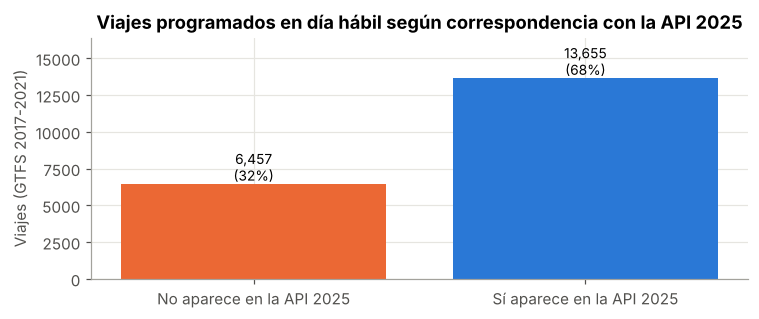

Rutas sin correspondencia con más viajes (posible cambio de código):


,route_short_name,route_long_name,viajes_dia_habil
94,T47B,Terminal Andrés Sanín - Estación Unidad Deportiva,488
96,T57A,Estación Nuevo Latír - Estación Unidad Deportiva,378
70,P21B,Terminal Menga - Estación Universidades,333
93,T42,Pizamos - Centro - Terminal,322
90,P84B,Terminal Andrés Sanín - Terminal Calipso,288
63,P10A,Estación Universidades - Centro,266
74,P27C,Terminal Menga - Estación Universidades,261
55,A85,Estación Santa Mónica - Terminal Andrés Sanín,243


In [30]:
g = pd.read_csv(G / "gold_rutas.csv", dtype={"route_id": str})
res = g.groupby("en_api_2025").agg(rutas=("route_id", "size"), viajes_dia_habil=("viajes_dia_habil", "sum"))
res.index = ["No aparece en la API 2025", "Sí aparece en la API 2025"]
display(res)

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(res.index, res["viajes_dia_habil"], color=[NARANJA, AZUL])
for i, v in enumerate(res["viajes_dia_habil"]):
    ax.text(i, v, f"{v:,}\n({v / res['viajes_dia_habil'].sum():.0%})", ha="center", va="bottom", fontsize=9)
ax.set_title("Viajes programados en día hábil según correspondencia con la API 2025")
ax.set_ylabel("Viajes (GTFS 2017-2021)")
ax.set_ylim(0, res["viajes_dia_habil"].max() * 1.2)
plt.tight_layout(); plt.show()

print("Rutas sin correspondencia con más viajes (posible cambio de código):")
display(g[~g["en_api_2025"]].nlargest(8, "viajes_dia_habil")[["route_short_name", "route_long_name", "viajes_dia_habil"]])

### 10.2 Accesibilidad: distancia a pie, población y movilidad reducida

El análisis (`src/transform/accesibilidad.py`) genera una malla de puntos cada 100 m dentro de cada comuna y mide la distancia en línea recta a la parada **vigente** más cercana (paradas de la API 2025). Con eso se calcula el porcentaje de área a 200, 300 y 500 m.

**Movilidad reducida:** el campo `GWheelchairBoarding` de la API existe pero no tiene datos. Se revisa aquí para justificarlo; como aproximación se usa la cobertura a 200 m.

In [31]:
api_raw = pd.read_csv(B / "api_stops_raw.csv", encoding="utf-8-sig", dtype=str)
print(f"Paradas en la API: {len(api_raw):,}")
print(f"Paradas con dato de silla de ruedas (GWheelchairBoarding): {api_raw['GWheelchairBoarding'].notna().sum():,}")

Paradas en la API: 2,107
Paradas con dato de silla de ruedas (GWheelchairBoarding): 0


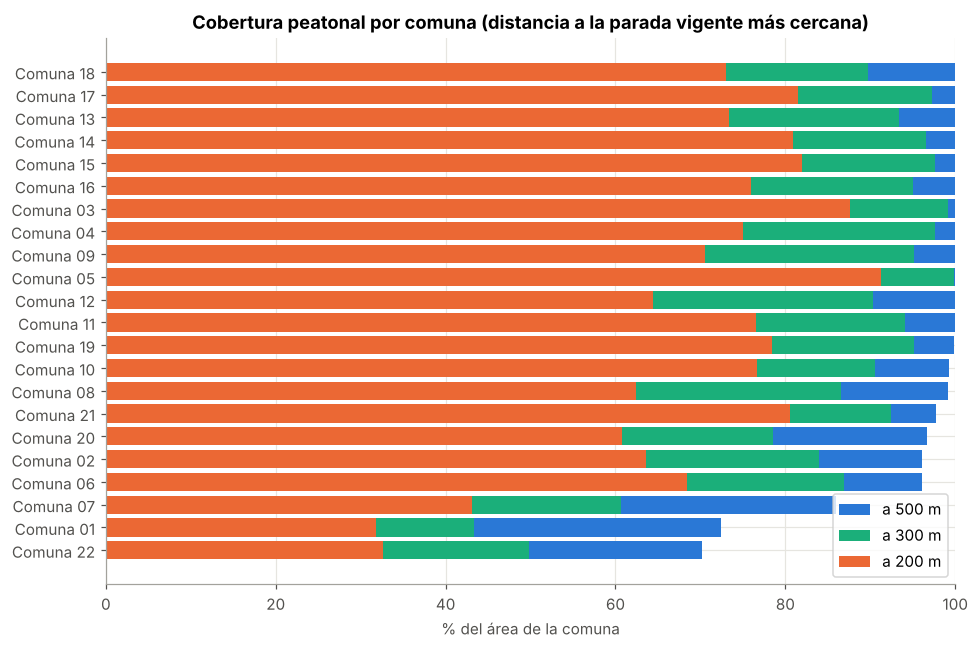

In [32]:
acc = pd.read_csv(G / "gold_accesibilidad.csv")
comunas = acc[acc["comuna_num"] > 0].sort_values("pct_area_500m")
radios = [c for c in acc.columns if c.startswith("pct_area_")]
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(comunas))
ax.barh(y, comunas["pct_area_500m"], color=AZUL, label="a 500 m")
ax.barh(y, comunas["pct_area_300m"], color=AQUA, label="a 300 m")
ax.barh(y, comunas["pct_area_200m"], color=NARANJA, label="a 200 m")
ax.set_yticks(y, comunas["comuna"])
ax.set_xlabel("% del área de la comuna")
ax.set_xlim(0, 100)
ax.set_title("Cobertura peatonal por comuna (distancia a la parada vigente más cercana)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

In [33]:
total = acc[acc["comuna_num"] == 0].iloc[0]
cols = ["comuna", "area_km2", "paradas_vigentes", "distancia_media_m", "distancia_p90_m", "pct_area_500m"]
if "poblacion" in acc.columns and acc["poblacion"].notna().any():
    cols += ["poblacion", "personas_cubiertas_500m", "personas_sin_cobertura_500m", "habitantes_por_parada"]
display(acc[cols].sort_values("pct_area_500m").head(6))
if pd.isna(total.get("poblacion", np.nan)):
    print("Población: no hay archivo data/bronze/poblacion_comunas.csv en esta ejecución; las columnas de población quedan vacías.")

,comuna,area_km2,paradas_vigentes,distancia_media_m,distancia_p90_m,pct_area_500m,poblacion,personas_cubiertas_500m,personas_sin_cobertura_500m,habitantes_por_parada
21,Comuna 22,10.69,57,401.0,891.0,70.2,29619,20780,8839,520.0
0,Comuna 01,2.86,24,516.0,1282.0,72.4,60445,43749,16696,2519.0
6,Comuna 07,5.27,40,272.0,529.0,86.0,70392,60508,9884,1760.0
22,Total Cali (comunas),119.75,1854,188.0,346.0,95.3,2192976,2140127,52849,1183.0
5,Comuna 06,5.35,83,177.0,346.0,96.1,151877,145915,5962,1830.0
1,Comuna 02,10.84,160,192.0,355.0,96.1,121578,116867,4711,760.0


### 10.3 Duración con promedios ponderados por número de viajes

Antes solo había un promedio simple por ruta. Ahora se muestran tres medidas, porque cada una responde una pregunta distinta:
- **Simple por ruta:** cada ruta cuenta igual, sin importar cuántos viajes hace.
- **Ponderada por viajes:** una ruta con más viajes pesa más. Es la que vive un pasajero promedio.
- **Mediana:** el viaje típico, sin que las rutas o viajes extremos la muevan.

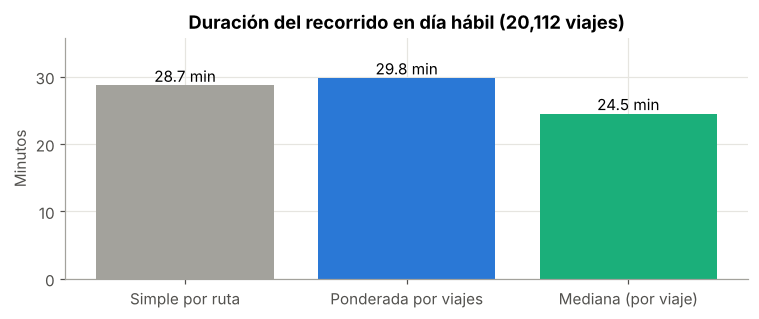

In [34]:
dur = k["KPI5_tiempo_recorrido_min"]
serie = pd.Series({"Simple por ruta": dur["simple_por_ruta_min"],
                   "Ponderada por viajes": dur["ponderada_por_viajes_min"],
                   "Mediana (por viaje)": dur["mediana_min"]})
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(serie.index, serie.values, color=[GRIS, AZUL, AQUA])
for i, v in enumerate(serie.values):
    ax.text(i, v, f"{v} min", ha="center", va="bottom")
ax.set_ylabel("Minutos")
ax.set_title(f"Duración del recorrido en día hábil ({dur['viajes_considerados']:,} viajes)")
ax.set_ylim(0, serie.max() * 1.2)
plt.tight_layout(); plt.show()

### 10.4 Diferencias y registros sin correspondencia, visibles

Las diferencias no se eliminan: se guardan en `gold_conciliacion_paradas` y `gold_conciliacion_rutas`, también en la base de datos, para que cualquier decisión se tome viendo lo que cambió.

In [35]:
cp = pd.read_csv(G / "gold_conciliacion_paradas.csv", dtype={"stop_id": str})
cr = pd.read_csv(G / "gold_conciliacion_rutas.csv", dtype={"route_id": str})
print("Paradas con diferencia:")
display(cp["motivo"].value_counts().rename("paradas").to_frame())
print("Rutas por estado:")
display(cr["estado"].value_counts().rename("rutas").to_frame())
print("Paradas reubicadas más de 200 m (las 5 más lejanas):")
display(cp[cp["motivo"] == "reubicada más de 200 m"].nlargest(5, "distancia_m")[["stop_id", "stop_name", "distancia_m", "comuna"]])

Paradas con diferencia:


,paradas
motivo,
solo en API 2025 (nueva),495
solo en GTFS 2017-2021,436
reubicada más de 200 m,14


Rutas por estado:


,rutas
estado,
en ambas fuentes,63
solo GTFS 2017-2021,34
solo API 2025 (sin horario en GTFS),31


Paradas reubicadas más de 200 m (las 5 más lejanas):


,stop_id,stop_name,distancia_m,comuna
5,511143,Via La Voragine Ecoparque 4 entrada,845.1,Fuera de comunas (rural)
6,511146,Via La Voragine Ecoparque 4 entrada,830.4,Fuera de comunas (rural)
9,511149,Via La Voragine Ecoparque 1 entrada,444.1,Fuera de comunas (rural)
1,511135,Cl 36 entre Kr 170 y 168,427.1,Fuera de comunas (rural)
7,511147,Via La Voragine Ecoparque 3 entrada,423.2,Fuera de comunas (rural)


## 11. Conclusiones y siguientes pasos

1. **Integración correcta:** la API no publica nombres de parada, así que el join por nombre producía 0 filas. Se cambió a la llave oficial `GStopID = stop_id`, validada geográficamente (mediana ≈ 10 m).
2. **Extracción completa:** la API estaba truncada en 2.000 registros. Se implementó paginación y una caché Bronze por si la API no responde.
3. **Horarios:** se procesan ≈3 M registros de `stop_times` por bloques. Se detectó y corrigió el solapamiento de `service_id`, que habría triplicado la frecuencia.
4. **Calidad:** las llaves vienen limpias. Los problemas reales son estructurales: columnas vacías, llaves distintas, versiones de diferentes años y programación duplicada.
5. **Comunas y accesibilidad:** las 22 comunas se asignan por *spatial join* y la cobertura peatonal se calcula con una malla de 100 m (sección 10.2).
6. **Limitación temporal:** el GTFS es de 2017-2021. Las frecuencias y los viajes describen esa programación; la API 2025 se usa para la ubicación de las paradas y la lista de rutas vigentes.
7. **Limitación de población:** depende del archivo que se descargue de datos.cali.gov.co. Sin él, el análisis de accesibilidad sigue funcionando, pero sin personas cubiertas.